# Hypergraph Sheaf Neural Networks

A graph edge relates exactly **two** nodes, but many interactions involve groups: the authors of a paper, the reactants of a chemical reaction, the members of a meeting. A **hypergraph** stores such group interactions directly as **hyperedges**, arbitrary subsets of nodes. **Sheaf Hypergraph Networks** (Duta et al., 2023) bring sheaves to this setting. Each node gets a different restriction map *for every group it belongs to*, so the same node can present itself differently in different contexts.

This is a **hands-on design notebook**. The data, the figures, and all *reference* computations below are executable. The neural layer at the end is deliberately left as a set of TODOs for you to implement: its methods raise `NotImplementedError`, and the default cells never call them.

### What You Will Learn
* Why clique expansion loses information, and how the incidence (bipartite) view keeps it.
* The linear and non-linear **sheaf hypergraph Laplacians**, their energies, and their inductive biases.
* How to build these operators densely, check their properties (symmetry, positive semi-definiteness, reduction to the classical hypergraph Laplacian), and spot a subtle normalization pitfall.
* Why sheaf diffusion avoids the oversmoothing of hypergraph diffusion, shown with a small diffusion experiment.
* How to structure your own sheaf hypergraph layer (TODO).

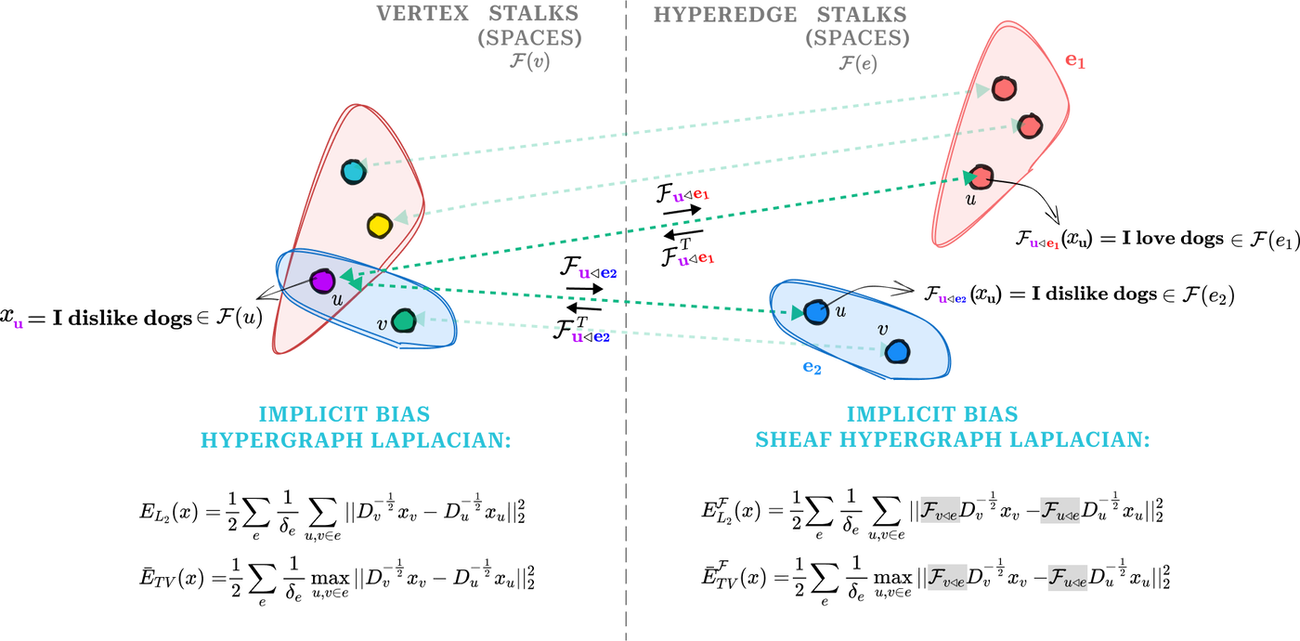

*A hypergraph sheaf: every node v has a vertex stalk F(v) = R^d, every hyperedge e a hyperedge stalk F(e) = R^d, and each incidence (v, e) a linear map F_{v<e}. The same node can be represented differently in each hyperedge it belongs to ("I dislike dogs" in e2 but "I love dogs" in e1). Classical hypergraph networks minimize an energy defined on the vertex space (left); sheaf hypergraph networks compare representations in the hyperedge stalks (right).*

<sub>Source: Duta et al. (2023), *Sheaf Hypergraph Networks*, [arXiv:2309.17116](https://arxiv.org/abs/2309.17116), appendix. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Hypergraph Sheaves and Their Laplacians](#3-laplacians)
    * [Incidence, Stalks, and Restriction Maps](#incidence-stalks)
    * [The Linear Sheaf Hypergraph Laplacian](#linear-laplacian)
    * [The Non-Linear Sheaf Hypergraph Laplacian](#nonlinear-laplacian)
4. [Dataset Pipeline](#4-dataset-pipeline)
    * [Incidence Lists](#incidence-lists)
    * [What Clique Expansion Loses](#clique-expansion)
5. [Reference Computations](#5-reference)
    * [Building the Linear Sheaf Laplacian](#building-laplacian)
    * [A Normalization Pitfall](#normalization-pitfall)
    * [The Non-Linear Laplacian's Pair Selection](#pair-selection)
6. [Inductive Bias: Oversmoothing vs. Global Sections](#6-inductive-bias)
7. [Model Backbone (TODO)](#7-backbone)
8. [Training Pipeline (TODO)](#8-training)
9. [Reproducibility and Exercises](#9-exercises)

<a id="1-introduction"></a>
# 1. Introduction

The simplest way to feed a hypergraph to a GNN is **clique expansion**: replace every hyperedge by all pairwise edges among its members. Clique expansion forgets *which group* produced each pairwise edge. Three people who all co-authored one paper look exactly like three people who co-authored three separate papers in pairs. Section 4.2 makes this concrete.

The **incidence** view keeps the groups. A hypergraph is a bipartite graph between nodes and hyperedges, and message passing alternates *node → hyperedge → node*. Hypergraph neural networks such as HGNN and HyperGCN propagate with a **hypergraph Laplacian** built on this view. Like the graph Laplacian, it pulls the features of nodes sharing a hyperedge together, and stacking layers leads to oversmoothing.

Sheaf hypergraph networks attach a vector space to every node *and* every hyperedge, plus a restriction map for every incidence. Diffusion then minimizes disagreement **inside the hyperedge stalks**, after each node's features have been mapped there, rather than disagreement between raw node features.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

This notebook needs only PyTorch, NumPy, and Matplotlib: the repository does not yet ship a hypergraph sheaf model, which is exactly what Section 7 asks you to design.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import itertools
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# =====================================================================
# 2. Core Scientific Libraries & Reproducibility
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)  # noqa: NPY002
torch.manual_seed(SEED)
torch.set_num_threads(1)

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0


<a id="3-laplacians"></a>
# 3. Hypergraph Sheaves and Their Laplacians

<a id="incidence-stalks"></a>
### 3.1 Incidence, Stalks, and Restriction Maps

A hypergraph $\mathcal{H} = (\mathcal{V}, \mathcal{E})$ has hyperedges $e \subseteq \mathcal{V}$ of size (degree) $\delta_e = |e|$. A **hypergraph sheaf** assigns:
* a vertex stalk $\mathcal{F}(v) = \mathbb{R}^d$ to every node;
* a hyperedge stalk $\mathcal{F}(e) = \mathbb{R}^d$ to every hyperedge;
* a restriction map $\mathcal{F}_{v \trianglelefteq e}: \mathcal{F}(v) \to \mathcal{F}(e)$ to every incidence $v \in e$.

With hyperedges of size two, this is exactly the graph sheaf of notebook 1. In Sheaf Hypergraph Networks, the maps are predicted by an MLP from the node features and a hyperedge feature (for example the mean of its members' features), and the paper finds diagonal maps to work best in practice.

<a id="linear-laplacian"></a>
### 3.2 The Linear Sheaf Hypergraph Laplacian

The **linear** sheaf hypergraph Laplacian generalizes the HGNN operator. Acting on a 0-cochain $\mathbf{x}$, it reads

$$\mathcal{L}_\mathcal{F}(\mathbf{x})_v = \sum_{e \ni v} \frac{1}{\delta_e}\,\mathcal{F}_{v \trianglelefteq e}^{\top}\sum_{\substack{u \in e\\ u \neq v}}\big(\mathcal{F}_{v \trianglelefteq e}\mathbf{x}_v - \mathcal{F}_{u \trianglelefteq e}\mathbf{x}_u\big),$$

and diffusion with it reduces the **sheaf Dirichlet energy**

$$E_\mathcal{F}(\mathbf{x}) = \frac{1}{2}\sum_{e}\frac{1}{\delta_e}\sum_{u, v \in e}\big\|\mathcal{F}_{v \trianglelefteq e}\mathbf{x}_v - \mathcal{F}_{u \trianglelefteq e}\mathbf{x}_u\big\|^2.$$

The energy is small when the members of every hyperedge *agree in that hyperedge's stalk*, not when their raw features are equal. Two special cases anchor the definition:
* hyperedges of size two give the graph sheaf Laplacian of NSD;
* identity maps with $d = 1$ give the classical linear hypergraph Laplacian $\mathcal{L}(\mathbf{x})_v = \sum_{e \ni v}\frac{1}{\delta_e}\sum_{u \in e}(x_v - x_u)$.

In practice it is used in its symmetrically normalized form $\Delta_\mathcal{F} = D^{-1/2}\mathcal{L}_\mathcal{F}D^{-1/2}$, inside a layer $\mathbf{X}^{+} = \sigma\big((I - \Delta_\mathcal{F})(I \otimes W_1)\mathbf{X}W_2\big)$.

<a id="nonlinear-laplacian"></a>
### 3.3 The Non-Linear Sheaf Hypergraph Laplacian

The **non-linear** version follows HyperGCN. For every hyperedge, it keeps only the **two members that disagree most** in the hyperedge stalk,

$$(u^*, v^*) = \arg\max_{u, v \in e}\big\|\mathcal{F}_{u \trianglelefteq e}\mathbf{x}_u - \mathcal{F}_{v \trianglelefteq e}\mathbf{x}_v\big\|,$$

and builds a graph sheaf Laplacian on these selected pairs (plus mediator edges in some variants). Its energy is a total-variation-like quantity, $\max_{u,v \in e}\|\cdot\|^2$ instead of a sum, and it depends on the signal: the selected pairs change as $\mathbf{x}$ changes.

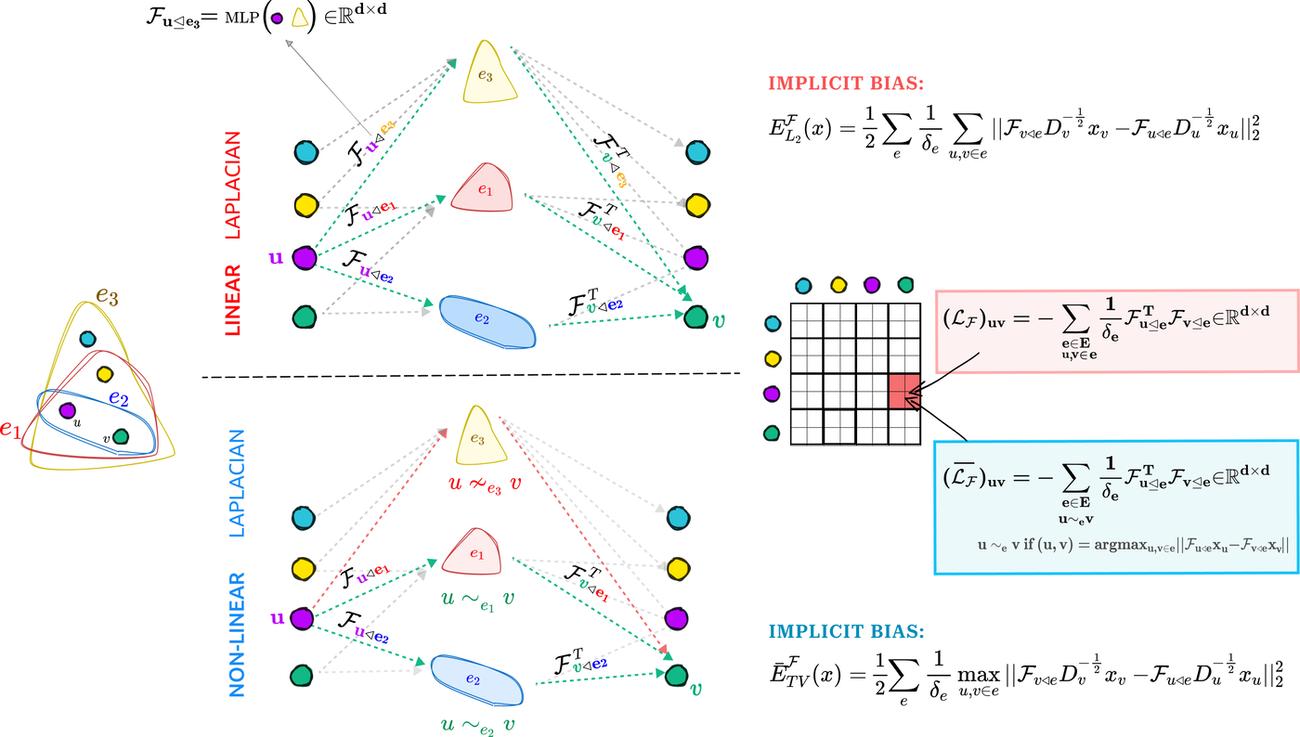

*Linear and non-linear sheaf hypergraph Laplacians. Top: in the linear case, the block (L_F)_uv accumulates contributions from every hyperedge that contains both u and v. Bottom: in the non-linear case, each hyperedge contributes only through its two most dissimilar nodes. Right: the implicit energies minimized by each diffusion.*

<sub>Source: Duta et al. (2023), *Sheaf Hypergraph Networks*, [arXiv:2309.17116](https://arxiv.org/abs/2309.17116), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline

<a id="incidence-lists"></a>
### 4.1 Incidence Lists

We store a hypergraph as an **incidence list**, a $[2, I]$ tensor of (node, hyperedge) pairs, which is the hypergraph counterpart of `edge_index`. Nodes and hyperedges have separate index ranges, and a node may belong to several hyperedges. Our toy has two overlapping groups of unequal size that share node 2.

In [2]:
# =====================================================================
# Two overlapping group interactions, with unequal group sizes
# =====================================================================
groups = [[0, 1, 2], [2, 3, 4, 5]]
num_nodes, num_hyperedges = 6, len(groups)
incidence = torch.tensor([(v, e) for e, group in enumerate(groups) for v in group]).T
node_signal = torch.tensor([[1.0], [2.0], [3.0], [-1.0], [0.0], [2.0]])
assert incidence.shape == (2, 7)

node_degree = torch.bincount(incidence[0], minlength=num_nodes)
edge_degree = torch.bincount(incidence[1], minlength=num_hyperedges)
print("Incidence [node, hyperedge]:\n", incidence)
print(f"Node degrees (hyperedges per node): {node_degree.tolist()}")
print(f"Hyperedge degrees delta_e:          {edge_degree.tolist()}")

Incidence [node, hyperedge]:
 tensor([[0, 1, 2, 2, 3, 4, 5],
        [0, 0, 0, 1, 1, 1, 1]])
Node degrees (hyperedges per node): [1, 1, 2, 1, 1, 1]
Hyperedge degrees delta_e:          [3, 4]


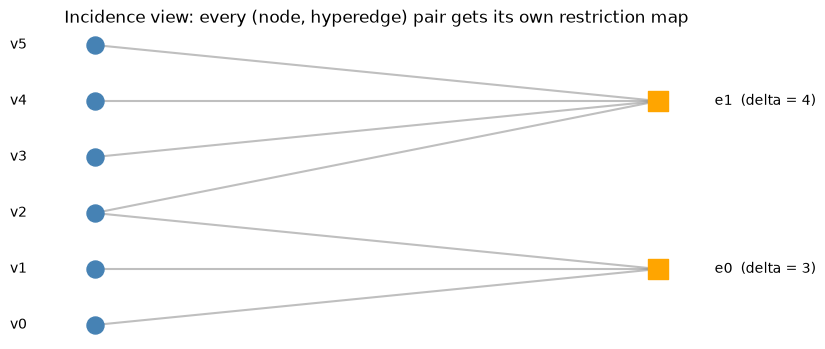

In [3]:
# =====================================================================
# Bipartite incidence diagram: nodes on the left, hyperedges on the right
# =====================================================================
fig, ax = plt.subplots(figsize=(8, 4))
for v in range(num_nodes):
    ax.scatter(0, v, s=150, color="steelblue", zorder=3)
    ax.text(-0.12, v, f"v{v}", ha="right", va="center")
for e, group in enumerate(groups):
    center = 1 + 3 * e
    ax.scatter(1, center, marker="s", s=220, color="orange", zorder=3)
    ax.text(1.1, center, f"e{e}  (delta = {len(group)})", va="center")
    for v in group:
        ax.plot([0, 1], [v, center], alpha=0.5, color="gray")
ax.set_title(
    "Incidence view: every (node, hyperedge) pair gets its own restriction map"
)
ax.axis("off")
plt.show()

<a id="clique-expansion"></a>
### 4.2 What Clique Expansion Loses

Compare two hypergraphs on three nodes:
* **$\mathcal{H}_1$**: one hyperedge $\{0, 1, 2\}$, a single three-way interaction;
* **$\mathcal{H}_2$**: three hyperedges $\{0, 1\}, \{1, 2\}, \{0, 2\}$, three separate pairwise interactions.

Their **clique expansions are identical** (a triangle), so any model working on the expanded graph cannot tell them apart. Their incidence matrices differ, and so do their hypergraph Laplacians, because $1/\delta_e$ weights a pair differently when it comes from a larger group.

In [4]:
# =====================================================================
# Same clique expansion, different hypergraphs
# =====================================================================
def clique_expansion(groups, n):
    A = torch.zeros(n, n)
    for g in groups:
        for u, v in itertools.permutations(g, 2):
            A[u, v] = 1.0
    return A


def incidence_matrix(groups, n):
    H = torch.zeros(n, len(groups))
    for e, g in enumerate(groups):
        H[g, e] = 1.0
    return H


def hypergraph_laplacian(groups, n):
    """Classical linear hypergraph Laplacian: L(x)_v = sum_e 1/delta_e sum_{u in e} (x_v - x_u)."""
    L = torch.zeros(n, n)
    for g in groups:
        for v in g:
            for u in g:
                if u != v:
                    L[v, v] += 1 / len(g)
                    L[v, u] -= 1 / len(g)
    return L


def rounded(values):
    """Plain floats rounded to 3 decimals (and -0.0 shown as 0.0)."""
    return [round(float(v), 3) + 0.0 for v in values]


H1, H2 = [[0, 1, 2]], [[0, 1], [1, 2], [0, 2]]
print(
    f"Clique expansions equal:  {torch.equal(clique_expansion(H1, 3), clique_expansion(H2, 3))}"
)
print(
    f"Incidence matrix shapes:  {tuple(incidence_matrix(H1, 3).shape)} vs {tuple(incidence_matrix(H2, 3).shape)}"
)
print(
    f"Laplacian spectrum of H1: {rounded(torch.linalg.eigvalsh(hypergraph_laplacian(H1, 3)))}"
)
print(
    f"Laplacian spectrum of H2: {rounded(torch.linalg.eigvalsh(hypergraph_laplacian(H2, 3)))}"
)

Clique expansions equal:  True
Incidence matrix shapes:  (3, 1) vs (3, 3)
Laplacian spectrum of H1: [0.0, 1.0, 1.0]
Laplacian spectrum of H2: [0.0, 1.5, 1.5]


<a id="5-reference"></a>
# 5. Reference Computations

<a id="building-laplacian"></a>
### 5.1 Building the Linear Sheaf Laplacian

The function below assembles $\mathcal{L}_\mathcal{F}$ as a dense $nd \times nd$ matrix from the operator form of Section 3.2. Each hyperedge contributes, for every ordered pair of distinct members $(v, u)$, a block $+\frac{1}{\delta_e}\mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}$ on the diagonal and $-\frac{1}{\delta_e}\mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{u \trianglelefteq e}$ off the diagonal. We then check three properties that any correct implementation, including yours in Section 7, should satisfy.

In [5]:
# =====================================================================
# Dense linear sheaf hypergraph Laplacian (operator form)
# =====================================================================
def sheaf_hypergraph_laplacian(groups, maps, n, d):
    """maps[(v, e)] is the d x d restriction map of node v into hyperedge e."""
    L = torch.zeros(n * d, n * d)
    for e, g in enumerate(groups):
        for v in g:
            Fv = maps[(v, e)]
            for u in g:
                if u == v:
                    continue
                Fu = maps[(u, e)]
                L[v * d : (v + 1) * d, v * d : (v + 1) * d] += Fv.T @ Fv / len(g)
                L[v * d : (v + 1) * d, u * d : (u + 1) * d] -= Fv.T @ Fu / len(g)
    return L


def sheaf_energy(groups, maps, x):
    """E_F(x) = 1/2 sum_e 1/delta_e sum_{u,v in e} ||F_v x_v - F_u x_u||^2 (ordered pairs)."""
    total = 0.0
    for e, g in enumerate(groups):
        for u, v in itertools.permutations(g, 2):
            total += ((maps[(v, e)] @ x[v] - maps[(u, e)] @ x[u]) ** 2).sum() / len(g)
    return 0.5 * total


# (a) identity maps with d = 1 recover the classical hypergraph Laplacian
identity = {(v, e): torch.eye(1) for e, g in enumerate(groups) for v in g}
L_id = sheaf_hypergraph_laplacian(groups, identity, num_nodes, 1)
print(
    f"(a) identity sheaf == classical hypergraph Laplacian: "
    f"{torch.allclose(L_id, hypergraph_laplacian(groups, num_nodes))}"
)

# (b) random maps in d = 2: symmetric and positive semi-definite
torch.manual_seed(0)
d = 2
random_maps = {(v, e): torch.randn(d, d) for e, g in enumerate(groups) for v in g}
L_F = sheaf_hypergraph_laplacian(groups, random_maps, num_nodes, d)
eig = torch.linalg.eigvalsh(L_F)
print(
    f"(b) symmetric: {torch.allclose(L_F, L_F.T)} | smallest eigenvalue: {eig.min():.2e} (>= 0 up to rounding)"
)

# (c) the quadratic form equals the sheaf Dirichlet energy
x = torch.randn(num_nodes, d)
print(
    f"(c) x^T L_F x == E_F(x): {torch.allclose(x.reshape(-1) @ L_F @ x.reshape(-1), sheaf_energy(groups, random_maps, x), atol=1e-4)}"
)

(a) identity sheaf == classical hypergraph Laplacian: True
(b) symmetric: True | smallest eigenvalue: 1.75e-07 (>= 0 up to rounding)
(c) x^T L_F x == E_F(x): True


<a id="normalization-pitfall"></a>
### 5.2 A Normalization Pitfall

Expanding the operator of Section 3.2 shows that each hyperedge adds $\frac{\delta_e - 1}{\delta_e}\,\mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}$ to the diagonal block of $v$: one term for each of the $\delta_e - 1$ other members. The block-matrix definition in Duta et al. (2023) writes this diagonal block as $\sum_e \frac{1}{\delta_e}\mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}$ instead. Mule et al. (2025, notebook 9) point out that, read literally, this matrix is **not** positive semi-definite once hyperedges have more than two members. The two readings agree only for graphs ($\delta_e = 2$). The cell below shows the difference on our toy with identity maps: the literal reading has negative eigenvalues, which would make "diffusion" amplify some signals. When you implement a layer, derive the matrix from the energy, as above.

In [6]:
# =====================================================================
# Literal block definition (diagonal 1/delta_e) vs the operator form
# =====================================================================
def literal_block_laplacian(groups, maps, n, d):
    L = torch.zeros(n * d, n * d)
    for e, g in enumerate(groups):
        for v in g:
            Fv = maps[(v, e)]
            L[v * d : (v + 1) * d, v * d : (v + 1) * d] += (
                Fv.T @ Fv / len(g)
            )  # 1/delta_e, not (delta_e-1)/delta_e
            for u in g:
                if u != v:
                    L[v * d : (v + 1) * d, u * d : (u + 1) * d] -= (
                        Fv.T @ maps[(u, e)] / len(g)
                    )
    return L


for name, L in [
    ("operator form", L_id),
    ("literal blocks", literal_block_laplacian(groups, identity, num_nodes, 1)),
]:
    ev = torch.linalg.eigvalsh(L)
    print(f"{name:<15} eigenvalues: {rounded(ev)}  -> PSD: {bool((ev > -1e-6).all())}")

operator form   eigenvalues: [0.0, 0.293, 1.0, 1.0, 1.0, 1.707]  -> PSD: True
literal blocks  eigenvalues: [-0.524, -0.11, 0.5, 0.5, 0.667, 0.967]  -> PSD: False


<a id="pair-selection"></a>
### 5.3 The Non-Linear Laplacian's Pair Selection

For the non-linear Laplacian, each hyperedge only connects its two most dissimilar members in the hyperedge stalk. With identity maps and the scalar signal of Section 4.1, this is simply the pair with the largest difference. With non-trivial maps, the *maps* decide what "dissimilar" means. The cell below computes the selected pair per hyperedge for both, which is the first step of a non-linear layer.

In [7]:
# =====================================================================
# Most discrepant pair per hyperedge, with identity and with random maps
# =====================================================================
def most_discrepant_pair(group, e, maps, x):
    scores = {
        (u, v): (maps[(u, e)] @ x[u] - maps[(v, e)] @ x[v]).norm().item()
        for u, v in itertools.combinations(group, 2)
    }
    return max(scores, key=lambda name: scores[name]), scores


torch.manual_seed(1)
scalar_maps = {(v, e): torch.randn(1, 1) for e, g in enumerate(groups) for v in g}
for e, g in enumerate(groups):
    pair_id, _ = most_discrepant_pair(g, e, identity, node_signal)
    pair_sh, _ = most_discrepant_pair(g, e, scalar_maps, node_signal)
    print(
        f"hyperedge e{e} {g}: identity maps select {pair_id} | random sheaf maps select {pair_sh}"
    )

edge_mean = torch.stack([node_signal[g].mean(0) for g in groups])
print(f"\nReference: identity-map hyperedge means = {edge_mean.flatten().tolist()}")
assert torch.allclose(edge_mean.flatten(), torch.tensor([2.0, 1.0]))

hyperedge e0 [0, 1, 2]: identity maps select (0, 2) | random sheaf maps select (0, 2)
hyperedge e1 [2, 3, 4, 5]: identity maps select (2, 3) | random sheaf maps select (2, 5)

Reference: identity-map hyperedge means = [2.0, 1.0]


<a id="6-inductive-bias"></a>
# 6. Inductive Bias: Oversmoothing vs. Global Sections

Why do sheaves help? Consider a hypergraph whose hyperedges each mix **two classes**, with a scalar feature $x_v = \pm 1$ given by the class. Hypergraph diffusion $\mathbf{x} \leftarrow \mathbf{x} - \alpha\Delta\mathbf{x}$ pulls the members of every hyperedge towards their average, which is zero, and erases the class signal: this is oversmoothing. Now give every node a one-dimensional restriction map equal to its class sign, $\mathcal{F}_{v \trianglelefteq e} = \pm 1$. In every hyperedge stalk, $\mathcal{F}_{v \trianglelefteq e}x_v = 1$ for all members, so the class signal has **zero sheaf energy**. It is a *global section*, and sheaf diffusion leaves it untouched while still smoothing away noise.

The experiment below adds noise to the signal and runs both diffusions with the normalized Laplacians, tracking the Dirichlet energy (as in the paper's depth study, shown after it) and the class separation $|\bar{x}_{+} - \bar{x}_{-}|$.

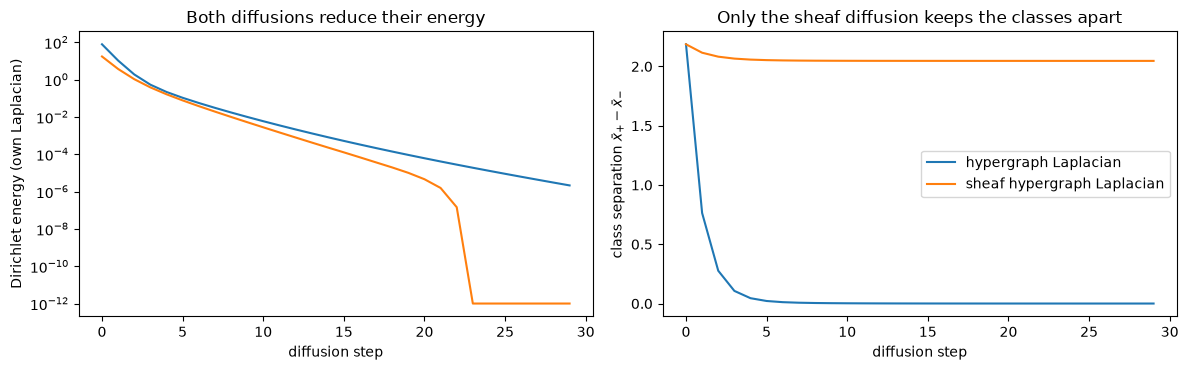

In [8]:
# =====================================================================
# Hypergraph diffusion vs sheaf diffusion on class-mixing hyperedges
# =====================================================================
torch.manual_seed(SEED)
n_h, n_e, size = 40, 30, 4
labels = torch.arange(n_h) % 2
mixed_groups = []
for _ in range(n_e):
    pos = torch.randperm(n_h // 2)[: size // 2] * 2  # two class-0 members
    neg = torch.randperm(n_h // 2)[: size // 2] * 2 + 1  # two class-1 members
    mixed_groups.append(torch.cat([pos, neg]).tolist())
sign = (1 - 2 * labels).float()  # +1 for class 0, -1 for class 1
x0 = sign + 0.6 * torch.randn(n_h)

graph_maps = {(v, e): torch.eye(1) for e, g in enumerate(mixed_groups) for v in g}
sheaf_maps = {
    (v, e): sign[v] * torch.eye(1) for e, g in enumerate(mixed_groups) for v in g
}


def normalized(L):
    deg = torch.diagonal(L).clamp_min(1e-12)
    return deg.rsqrt()[:, None] * L * deg.rsqrt()[None, :]


operators = {
    "hypergraph Laplacian": normalized(
        sheaf_hypergraph_laplacian(mixed_groups, graph_maps, n_h, 1)
    ),
    "sheaf hypergraph Laplacian": normalized(
        sheaf_hypergraph_laplacian(mixed_groups, sheaf_maps, n_h, 1)
    ),
}
steps, alpha = 30, 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, Delta in operators.items():
    x, energy, sep = x0.clone(), [], []
    for _ in range(steps):
        energy.append((x @ Delta @ x).item())
        sep.append((x[labels == 0].mean() - x[labels == 1].mean()).item())
        x = x - alpha * Delta @ x
    axes[0].semilogy(np.maximum(energy, 1e-12), label=name)
    axes[1].plot(sep, label=name)
axes[0].set(
    xlabel="diffusion step",
    ylabel="Dirichlet energy (own Laplacian)",
    title="Both diffusions reduce their energy",
)
axes[1].set(
    xlabel="diffusion step",
    ylabel=r"class separation $\bar{x}_{+} - \bar{x}_{-}$",
    title="Only the sheaf diffusion keeps the classes apart",
)
axes[1].legend()
plt.tight_layout()
plt.show()

Both diffusions do what diffusion does, reducing their own energy, but the two energies measure different things. Hypergraph diffusion reaches low energy by making all features similar, which destroys the class separation. Sheaf diffusion reaches low energy by making the features *consistent with the maps*, which preserves the separation and removes the noise around it. In a Sheaf Hypergraph Network the maps are **learned**, so the model can discover such consistent signals from data. The paper's ablation shows the same effect on a heterophilic benchmark, together with the observation that larger stalks help:

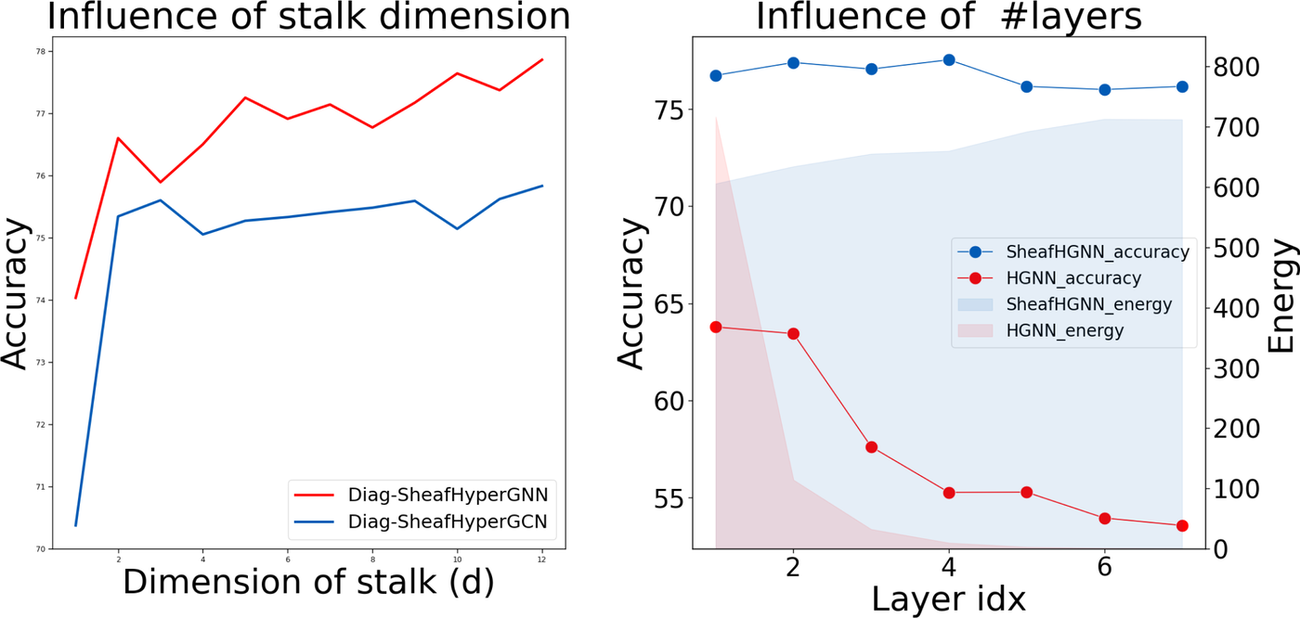

*Impact of stalk dimension and depth on a heterophilic synthetic dataset. Left: accuracy grows with the stalk dimension d. Right: as layers are added, HGNN's accuracy drops while its Dirichlet energy collapses towards zero (oversmoothing), whereas SheafHGNN keeps both its accuracy and its feature diversity.*

<sub>Source: Duta et al. (2023), *Sheaf Hypergraph Networks*, [arXiv:2309.17116](https://arxiv.org/abs/2309.17116), Fig. 2. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

<a id="7-backbone"></a>
# 7. Model Backbone (TODO)

Now design your own layer. Complete each TODO with a clearly documented shape contract, and do not replace the group interaction with a clique without explaining the change in semantics. A good plan is to implement one method at a time and test it against the reference computations of Section 5:
1. `restriction_maps`: predict one map per incidence, from the node feature and a hyperedge summary (for example the mean of its members). Start with diagonal maps, the paper's best choice.
2. `node_to_hyperedge`: map every member into the hyperedge stalk and aggregate. With identity maps, the result must match the hyperedge means of Section 5.3.
3. `hyperedge_to_node`: pull back with $\mathcal{F}^{\top}$ and normalize by degrees, so that one full step reproduces $\Delta_\mathcal{F}$ (check against `sheaf_hypergraph_laplacian`).
4. `forward`: combine transport, aggregation, and a residual update $\mathbf{X}^{+} = \mathbf{X} - \alpha\,\sigma(\Delta_\mathcal{F}\,\mathbf{Z})$ with $\mathbf{Z} = W_1\mathbf{X}W_2$.

In [9]:
class HypergraphSheafLayer(torch.nn.Module):
    def __init__(self, stalk_dim=2, hidden_dim=8):
        super().__init__()
        self.stalk_dim, self.hidden_dim = stalk_dim, hidden_dim
        # TODO: register trainable incidence-map learner and feature transforms.

    def restriction_maps(self, x_stalk, incidence):
        """Input [N,d,f], [2,I]; return one [d,d] map per incidence."""
        raise NotImplementedError("TODO: learn maps from node and hyperedge context")

    def node_to_hyperedge(self, x_stalk, incidence, maps):
        """Return transported, normalized hyperedge states [M,d,f]."""
        raise NotImplementedError("TODO: scatter transported incidence features")

    def hyperedge_to_node(self, edge_stalk, incidence, maps):
        """Return aggregated node messages [N,d,f]."""
        raise NotImplementedError("TODO: pull back messages; normalize degrees")

    def forward(self, x_stalk, incidence, tails=None, heads=None):
        # TODO: compose transport, aggregation, and the residual update.
        # For directed hypergraphs (notebook 9), decide how tails and heads enter.
        raise NotImplementedError(
            "TODO: compose transport, aggregation, residual update"
        )


class HypergraphSheafModel(torch.nn.Module):
    def __init__(self, in_channels=1, out_channels=2, stalk_dim=2, hidden_dim=8):
        super().__init__()
        self.stalk_dim, self.hidden_dim = stalk_dim, hidden_dim
        self.encoder = torch.nn.Linear(in_channels, stalk_dim * hidden_dim)
        self.layer = HypergraphSheafLayer(stalk_dim, hidden_dim)
        self.decoder = torch.nn.Linear(stalk_dim * hidden_dim, out_channels)

    def forward(self, x, incidence, tails=None, heads=None):
        h = self.encoder(x).reshape(-1, self.stalk_dim, self.hidden_dim)
        h = self.layer(h, incidence, tails=tails, heads=heads)
        return self.decoder(h.reshape(x.size(0), -1))


backbone = HypergraphSheafModel()
print(backbone)
print("Backbone only: the forward pass is intentionally TODO.")

HypergraphSheafModel(
  (encoder): Linear(in_features=1, out_features=16, bias=True)
  (layer): HypergraphSheafLayer()
  (decoder): Linear(in_features=16, out_features=2, bias=True)
)
Backbone only: the forward pass is intentionally TODO.


<a id="8-training"></a>
# 8. Training Pipeline (TODO)

1. Generate labels from a group-level rule (for example the class-mixing hypergraph of Section 6), then define disjoint node masks.
2. Implement the layer and verify it against the reference computations: identity-map hyperedge means (Section 5.3), the dense Laplacian (Section 5.1), and positive semi-definiteness (Section 5.2).
3. Add Adam, masked cross-entropy, validation-based checkpoint selection, and a single held-out test evaluation, as in notebooks 2 to 7.
4. Plot losses and probabilities only after implementing and training the model.

No model scores are supplied, because this backbone has not been implemented.

In [10]:
RUN_STUDENT_IMPLEMENTATION = False
if RUN_STUDENT_IMPLEMENTATION:
    # TODO: implement the layer before enabling this exercise.
    logits = backbone(node_signal, incidence)
    assert logits.shape == (num_nodes, 2)

<a id="9-exercises"></a>
# 9. Reproducibility and Exercises

Record the seed, the hyperedge membership, the normalization, the stalk widths, and the update rule. Test your implementation for: node and hyperedge permutations (the outputs must permute accordingly), duplicate incidences, singleton hyperedges ($\delta_e = 1$ contributes nothing), isolated nodes, finite gradients, and device transfers. For hyperedges of size two, compare against the graph sheaf Laplacian of the repository's NSD layers under matching normalization.

**Key takeaways**
* Clique expansion forgets which group produced an interaction; the incidence view and hypergraph sheaves keep it.
* The linear sheaf hypergraph Laplacian reduces disagreement *inside hyperedge stalks*. Derive its matrix from the energy to keep it positive semi-definite.
* Learned restriction maps turn class-mixing hyperedges from a source of oversmoothing into a source of consistent signal.

### Exercises
1. Explain how the shared node 2 couples the two groups of Section 4.1, and how its two restriction maps can give it different "roles" in each group.
2. Rerun Section 6 with hyperedges of size 6 and with unbalanced classes inside each hyperedge. Does sheaf diffusion still preserve the separation, and why?
3. Implement the TODO layer with diagonal maps, then compare it with an HGNN-style layer (identity maps) on the hypergraph of Section 6.
4. Extension: allow hyperedge stalks of a different dimension than node stalks ($\mathcal{F}_{v \trianglelefteq e} \in \mathbb{R}^{d_e \times d}$). Which parts of the tensor contract must change, and how would you batch it?